In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
sns.set_style('whitegrid')
plt.rcParams["figure.figsize"] = (12,6)

In [3]:
# load the data 
df = pd.read_csv('../Data/telco_comm_churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Basic info

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.shape

(7043, 21)

In [6]:
print("Missing Values")
df.isnull().sum()

Missing Values


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
print("Target Value Distribution")
print(df['Churn'].value_counts())

Target Value Distribution
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
print(f"Churn Rate[yes]: {df['Churn'].value_counts(normalize=True)['Yes']*100:.2f}%")
print(f"Churn Rate[No]: {df['Churn'].value_counts(normalize=True)['No']*100:.2f}%")

Churn Rate[yes]: 26.54%
Churn Rate[No]: 73.46%


## Analysis Numerical Features

In [9]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges']

In [10]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [11]:
df[numerical_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### visualize target variable

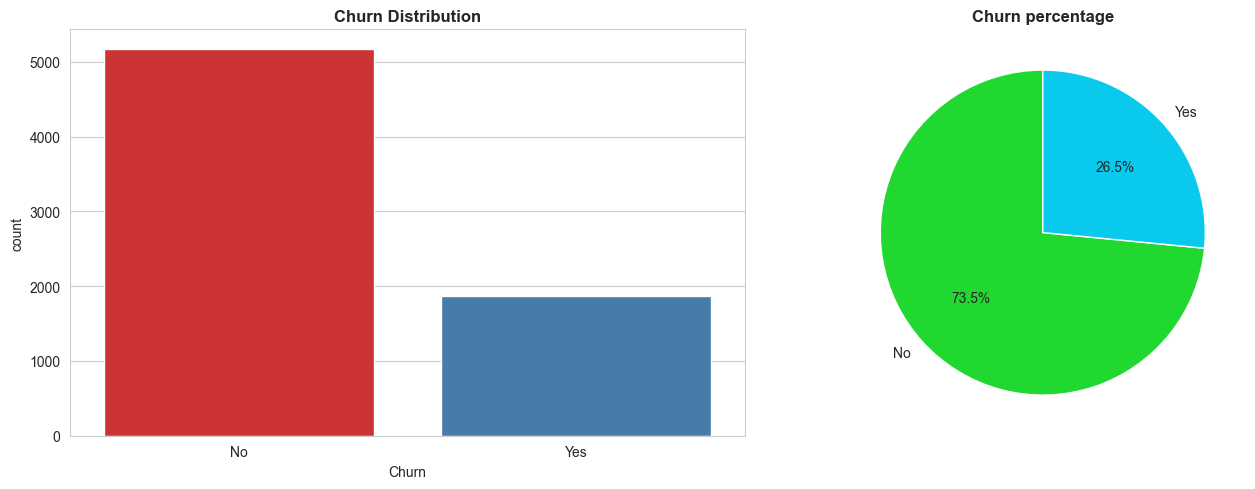

Saved: reports/churn_distribution.png


In [12]:
fig,ax = plt.subplots(1,2,figsize=(14,5))
sns.countplot(data= df, x= 'Churn', ax=ax[0], palette='Set1')
ax[0].set_title('Churn Distribution', fontweight='bold')
ax[0].set_ylabel('count')
churn_counts = df['Churn'].value_counts()
ax[1].pie(churn_counts, labels=churn_counts.index,
          autopct= '%1.1f%%',
          startangle= 90,
          colors=['#21d830', "#09caec"])
ax[1].set_title('Churn percentage', fontweight='bold')

plt.tight_layout()

#save
plt.savefig('../reports/churn_distribution.png', dpi=300 , bbox_inches='tight')
plt.show()


print(f"Saved: reports/churn_distribution.png")

## Numerical Features v/s Churn

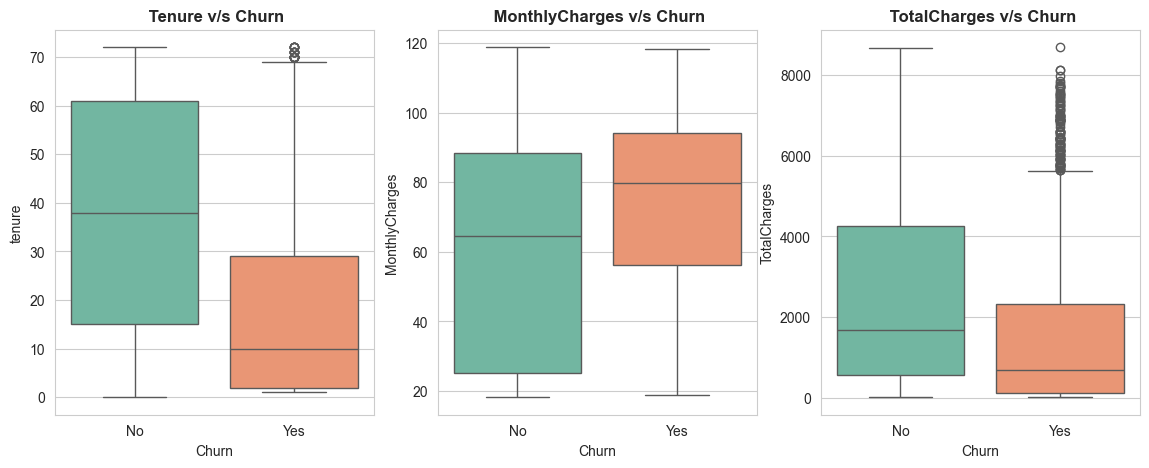

Saved: reports/churn_distribution.png


In [13]:
fig,ax = plt.subplots(1,3,figsize=(14,5))

# First graph tenure
sns.boxplot(data= df, x= 'Churn',y='tenure', ax=ax[0], palette='Set2')
ax[0].set_title(' Tenure v/s Churn', fontweight='bold')

# Second graph MonthlyCharges
sns.boxplot(data= df, x= 'Churn',y='MonthlyCharges' ,ax=ax[1], palette='Set2')
ax[1].set_title(' MonthlyCharges v/s Churn', fontweight='bold')

# Third graph TotalCharges 

sns.boxplot(data= df, x= 'Churn',y='TotalCharges', ax=ax[2], palette='Set2')
ax[2].set_title(' TotalCharges v/s Churn', fontweight='bold')
#save
plt.savefig('../reports/numerical_analysis.png', dpi=300 , bbox_inches='tight')
plt.show()


print(f"Saved: reports/churn_distribution.png")

## Analysis Catagorical Features

In [14]:
catagorical_cols = df.select_dtypes(include=['object']).columns.to_list()
catagorical_cols

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [15]:
catagorical_cols.remove('customerID')
catagorical_cols.remove('Churn')

In [16]:
print(f"Catagorical columns ({len(catagorical_cols)}): {catagorical_cols}")

Catagorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


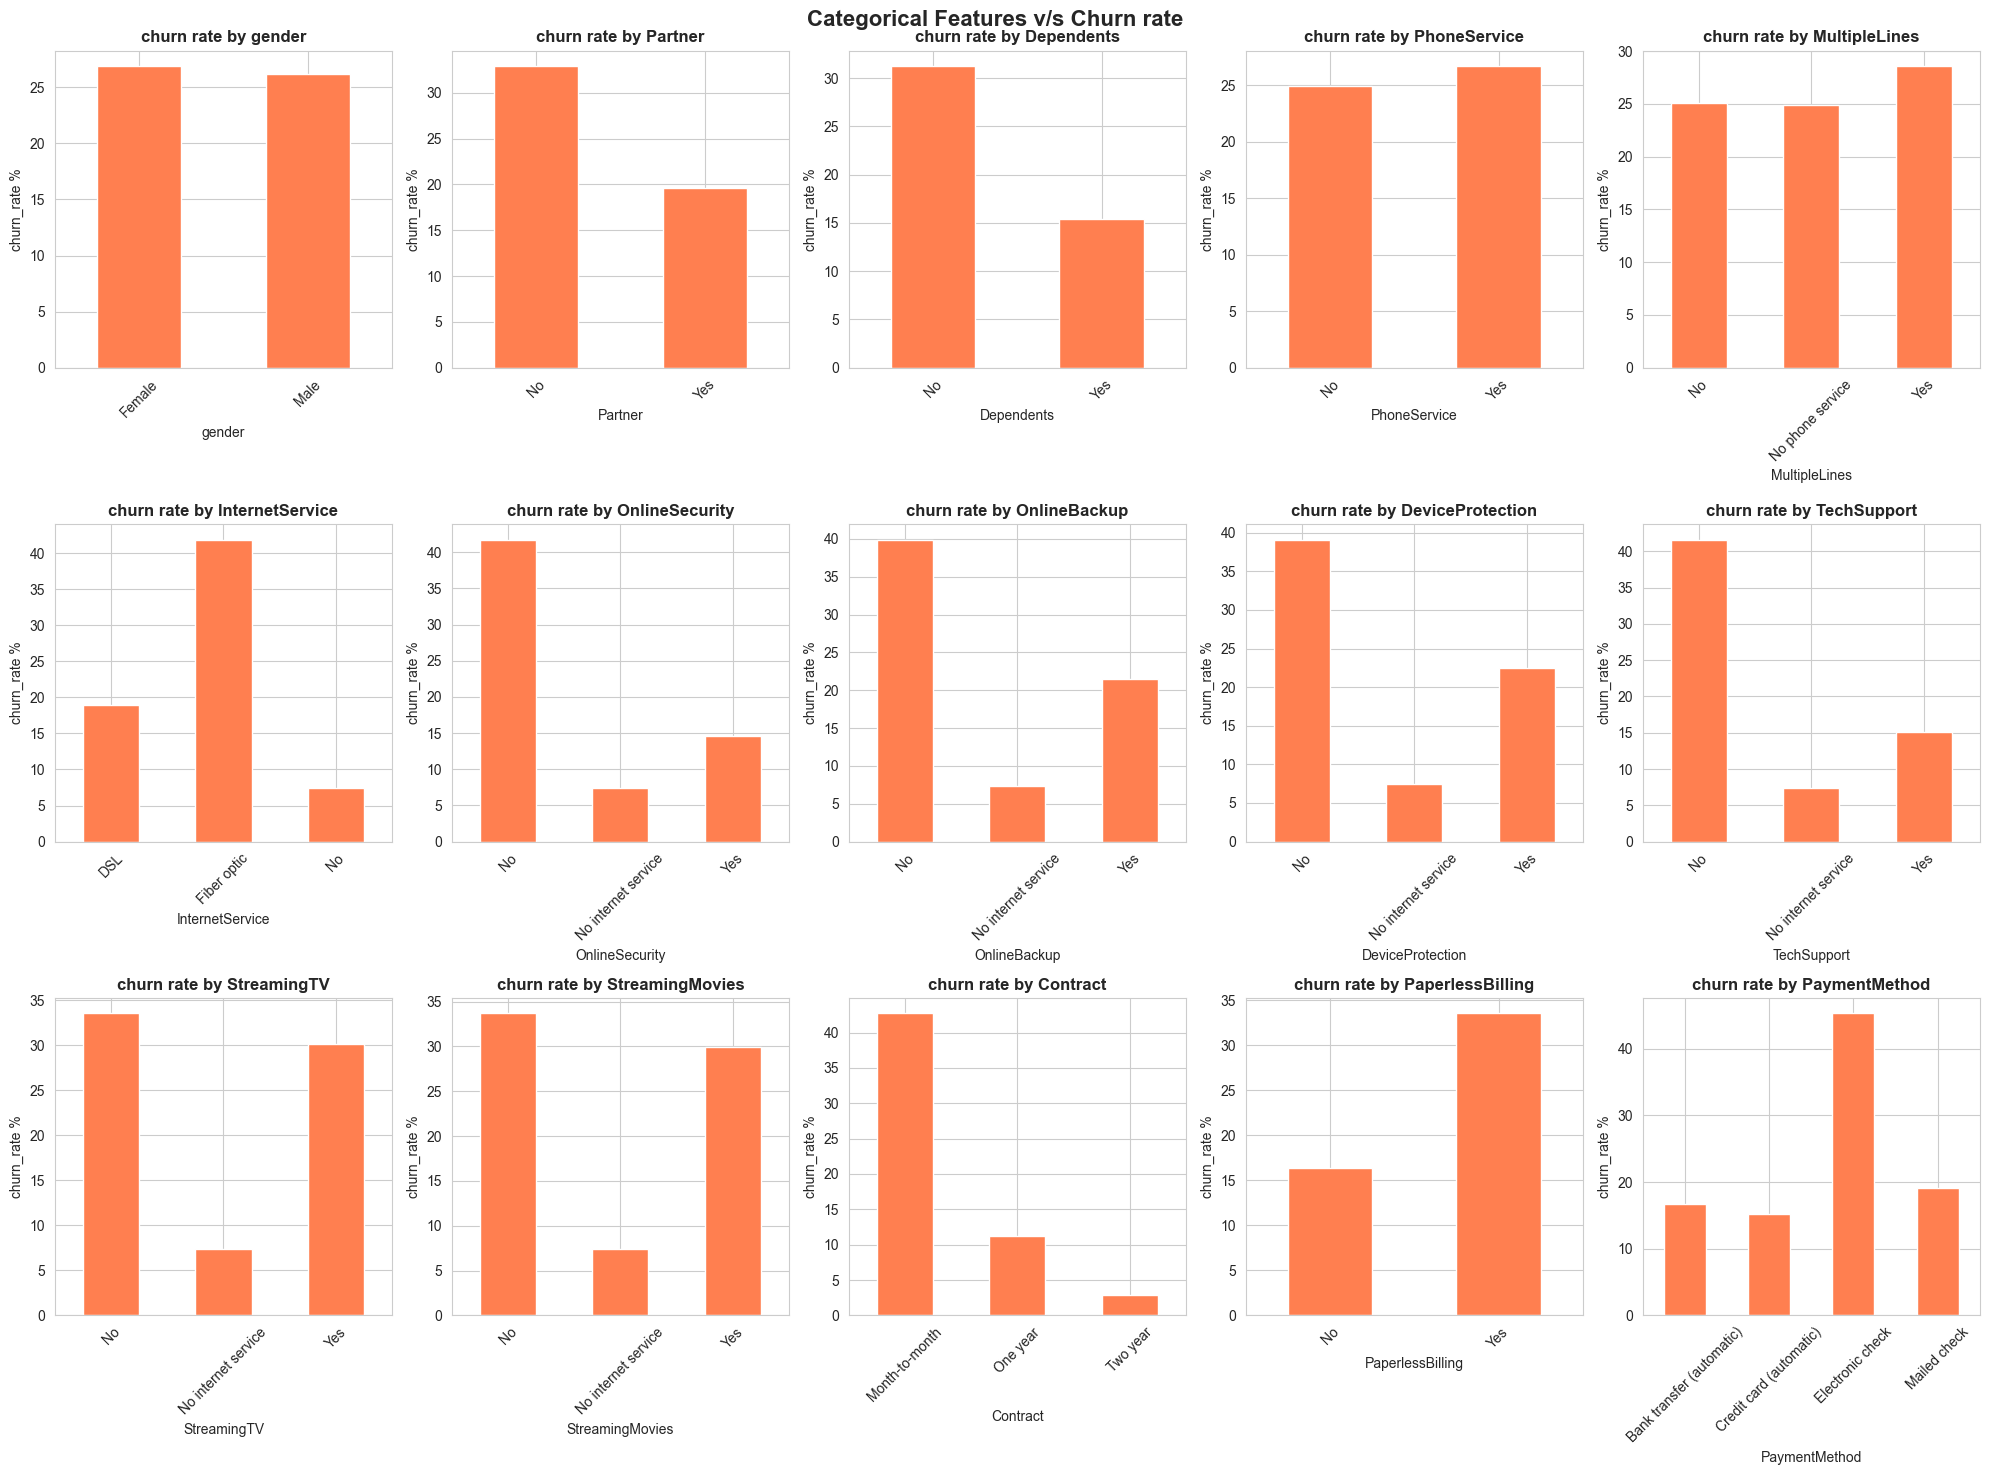

In [17]:
fig,ax = plt.subplots(3,5,figsize=(20,15))
ax = ax.flatten()
for idx, col in enumerate(catagorical_cols):
    churn_rate = df.groupby(col)['Churn'].apply(lambda x: (x=='Yes').sum()/len(x)*100)
    churn_rate.plot(kind='bar',ax=ax[idx],color= 'coral')
    ax[idx].set_title(f'churn rate by {col}',fontweight='bold')
    ax[idx].set_ylabel('churn_rate %')
    ax[idx].set_xlabel(col)
    ax[idx].tick_params(axis= 'x', rotation= 45)

plt.suptitle('Categorical Features v/s Churn rate', fontsize=16, fontweight='bold')
plt.tight_layout()
#save
plt.savefig('../reports/catagorical_analysis.png', dpi=300 , bbox_inches='tight')
plt.show()
 

In [18]:
df_corr = df.copy()
df_corr['Churn'] = df_corr['Churn'].map({'Yes':1, 'No':0})
df_corr['Churn']

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [19]:
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges','Churn']
corr_matrix = df_corr[numerical_features].corr()
corr_matrix

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.825880,0.651065,1.000000,-0.199484
Churn,-0.352229,0.193356,-0.199484,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

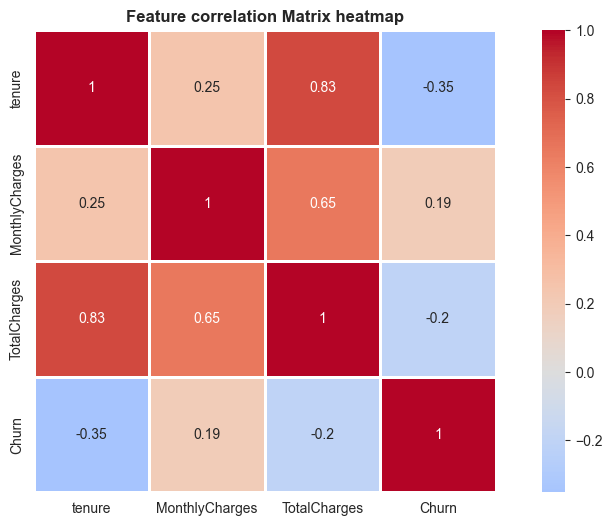

In [20]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0 , square=True,linewidths=1)
plt.title("Feature correlation Matrix heatmap", fontweight='bold')
plt.savefig('../reports/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show

NOTE: A multicolinearity between 'tenure' and 'total charges'

In [21]:
print("="*60)
print("KEY INSIGHTS FROM EDA")
print("="*60)


print(f'\n1. Dataset size: {df.shape[0]} customrs, {df.shape[1]} features')
print(f"2. Churn rate: {(df['Churn']=='Yes').sum()/len(df)*100:.2f}%")
print(f"3. Missing values: {df.isnull().sum().sum()} total")


avg_tenure_churn = df[df['Churn'] == 'Yes']['tenure'].mean() 
avg_tenure_no_churn = df[df['Churn'] == 'No']['tenure'].mean() 

print(f"4. Average tenure (churned): {avg_tenure_churn:.1f} months")
print(f"5. Average tenure (Not churned): {avg_tenure_no_churn:.1f} months")

avg_monthly_churn = df[df['Churn'] == 'Yes']['MonthlyCharges'].mean() 
avg_monthly_no_churn = df[df['Churn'] == 'No']['MonthlyCharges'].mean() 

print(f"6. Average Monthly Charges (churned): ${avg_monthly_churn:.1f} ")
print(f"7. Average Monthly Charges (Not churned): ${avg_monthly_no_churn:.1f} \n")

print("="*60)
print("A holistic analysis reveals that short-term, high-cost digital\nservices (Fiber Optic/Electronic Checks) are the primary churn\ndrivers, while long-term tenure and value-added security\nservices are the strongest indicators of customer loyalty.")
print("="*60)

print("="*60)
print("EDA COMPLETED")
print("="*60)


KEY INSIGHTS FROM EDA

1. Dataset size: 7043 customrs, 21 features
2. Churn rate: 26.54%
3. Missing values: 11 total
4. Average tenure (churned): 18.0 months
5. Average tenure (Not churned): 37.6 months
6. Average Monthly Charges (churned): $74.4 
7. Average Monthly Charges (Not churned): $61.3 

A holistic analysis reveals that short-term, high-cost digital
services (Fiber Optic/Electronic Checks) are the primary churn
drivers, while long-term tenure and value-added security
services are the strongest indicators of customer loyalty.
EDA COMPLETED
